# 12. Domain and general testing

<Axes: title={'center': 'Domain vs general perplexity'}, xlabel='model', ylabel='perplexity'>

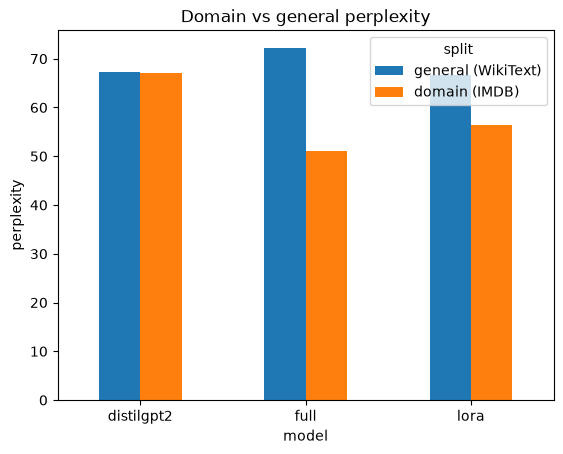

In [1]:
import pandas as pd
ev = pd.read_json("../outputs/eval_results.jsonl", lines=True).drop_duplicates(["model", "split"], keep="last")
ev["model"] = ev["model"].str.replace("outputs/", "").str.replace("/model", "")

ppl = ev.pivot_table(index="model", columns="split", values="perplexity").rename(
    columns={"test": "domain (IMDB)", "general": "general (WikiText)"})
base = ppl.loc["distilgpt2"]
change = ((ppl / base - 1) * 100).round(1).add_suffix(" Δ% vs base")
pd.concat([ppl.round(1), change], axis=1)
ppl.plot.bar(rot=0, ylabel="perplexity", title="Domain vs general perplexity")